# Predicting Telecom Customer Churn, and Deciding Who to Call
### Gradient boosting vs. a linear baseline, SHAP explanations, and a profit-based decision threshold

**Business problem.** A telecom company loses about a quarter of its customers every year. Winning a customer back costs far more than keeping one, but a retention offer (a call plus a discount) is not free, so it cannot be sent to everyone.

**Objective.** Build a model that scores each customer's probability of churning, explain *why* the score is high, and convert the scores into a concrete decision: **who should receive a retention offer so that expected profit is highest**.

**Why this notebook is different from a typical churn notebook**
* Models are compared with cross-validation and **fold-to-fold spread**, not one lucky split, and the test set is touched exactly once at the end.
* The decision threshold comes from a **cost model**, not from the default 0.5.
* Predictions are explained with **SHAP**, so the retention team knows what to say, not just whom to call.

**Outline**
1. Data and exploration
2. Cleaning and feature engineering
3. Model comparison (logistic regression, random forest, XGBoost, LightGBM)
4. Tuning and final test evaluation, with confidence intervals
5. Explaining the model with SHAP
6. From probabilities to profit: choosing the threshold
7. Findings, recommendations and limitations

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import xgboost as xgb
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
rng = np.random.default_rng(SEED)

FIG_DIR = Path("figures")
OUT_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"stay": "#4c72b0", "churn": "#dd8452"}
MODEL_COLORS = {"Logistic regression": "#8c8c8c", "Random forest": "#55a868", "XGBoost": "#937860", "LightGBM": "#4c72b0",
                "LightGBM, no engineered features": "#8172b3", "LightGBM (tuned)": "#dd8452"}

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

print("lightgbm", lgb.__version__, "| xgboost", xgb.__version__, "| shap", shap.__version__)

C:\Users\guerr\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


lightgbm 4.7.0 | xgboost 3.4.1 | shap 0.52.0


## 1. Data and exploration

The data is the public **IBM / Kaggle Telco Customer Churn** table: one row per customer of a fictional telecom, with demographics, the services they subscribe to, their contract and billing, and whether they **churned** (left) in the last month.

* **Target:** `Churn` (Yes/No). Roughly one customer in four churns, so the classes are imbalanced and plain accuracy would be misleading.
* **Features:** tenure, contract type, internet service, add-on services, payment method and charges.

In [2]:
def find_csv(name):
    # Kaggle mounts attached datasets under /kaggle/input; locally the file sits in ./data
    for root in (Path("/kaggle/input"), Path("data")):
        if root.exists():
            hits = sorted(root.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found. Attach the 'blastchar/telco-customer-churn' dataset or place the CSV in ./data")

raw = pd.read_csv(find_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv"))
print(raw.shape)
print("Duplicate customer IDs:", raw.customerID.duplicated().sum())
print("Missing values per column:", raw.isna().sum().sum())
raw.head()

(7043, 21)
Duplicate customer IDs: 0
Missing values per column: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.dtypes.to_frame("dtype").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,...,str,str,str,str,str,str,str,float64,str,str


`TotalCharges` is stored as text, which usually means something non-numeric is hiding in it. Let's look.

In [4]:
bad = raw[pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()]
print(f"{len(bad)} rows have a blank TotalCharges")
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head(5)

11 rows have a blank TotalCharges


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No


All of these customers have **tenure = 0**: they signed up this month and have not been billed yet, so their total charges are genuinely zero rather than unknown. We set them to 0 instead of dropping them or imputing a mean.

Next, who churns? The target balance and the strongest-looking single drivers:

Overall churn rate: 26.5%  (1,869 of 7,043 customers)


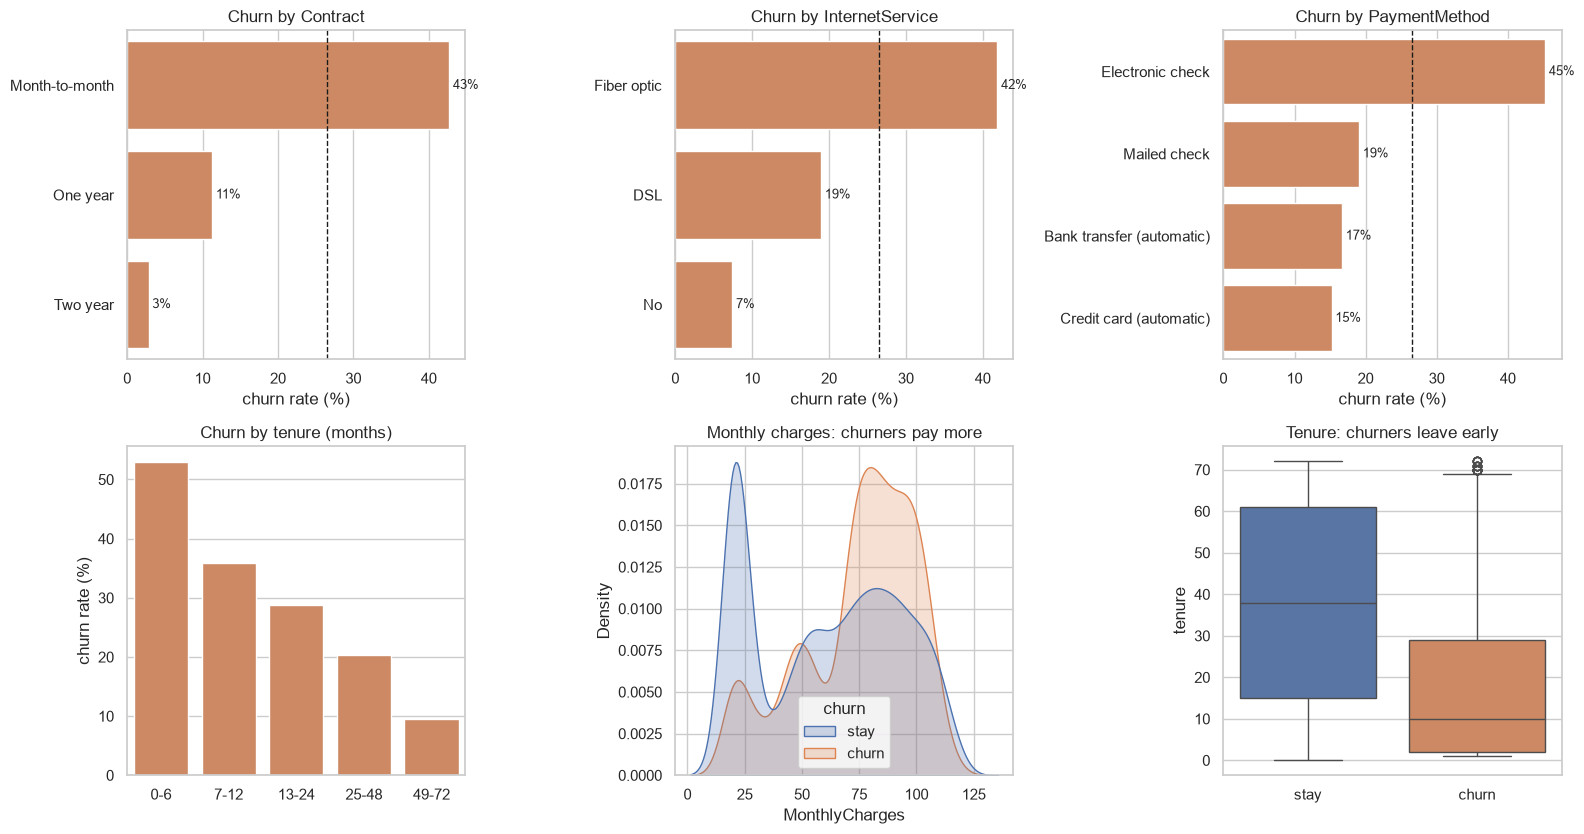

In [5]:
df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)
df["churn"] = (df["Churn"] == "Yes").astype(int)
print(f"Overall churn rate: {df.churn.mean():.1%}  ({df.churn.sum():,} of {len(df):,} customers)")
label = df.churn.map({0: "stay", 1: "churn"})

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.flat[:3], ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col).churn.mean().sort_values(ascending=False)
    sns.barplot(x=rate.values * 100, y=rate.index, ax=ax, color=PALETTE["churn"])
    ax.axvline(df.churn.mean() * 100, color="k", ls="--", lw=1)
    ax.set_xlabel("churn rate (%)"); ax.set_ylabel(""); ax.set_title(f"Churn by {col}")
    for i, v in enumerate(rate.values):
        ax.text(v * 100 + 0.5, i, f"{v:.0%}", va="center", fontsize=9)

tenure_band = pd.cut(df.tenure, [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
rate = df.groupby(tenure_band, observed=True).churn.mean() * 100
sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axes[1, 0], color=PALETTE["churn"])
axes[1, 0].set_title("Churn by tenure (months)"); axes[1, 0].set_ylabel("churn rate (%)"); axes[1, 0].set_xlabel("")

sns.kdeplot(data=df, x="MonthlyCharges", hue=label, fill=True, common_norm=False, palette=PALETTE, ax=axes[1, 1])
axes[1, 1].set_title("Monthly charges: churners pay more")

sns.boxplot(data=df, x=label, y="tenure", hue=label, palette=PALETTE, legend=False, ax=axes[1, 2], order=["stay", "churn"])
axes[1, 2].set_title("Tenure: churners leave early"); axes[1, 2].set_xlabel("")
save_fig("eda_overview.png")

**What the exploration says.** Churn is concentrated in **month-to-month contracts**, **fiber-optic internet**, **electronic-check payers** and **new customers**. Churners also pay higher monthly charges. These effects overlap (new customers are mostly on month-to-month plans), which is exactly why we use a multivariate model and SHAP later instead of reading each bar chart in isolation.

## 2. Cleaning and feature engineering

* The "No internet service" / "No phone service" levels of the add-on columns carry the same information as `InternetService` / `PhoneService`, so they are folded into "No". This removes redundant columns.
* Binary Yes/No columns become 0/1; the three multi-level columns (`InternetService`, `Contract`, `PaymentMethod`) are one-hot encoded.
* Three engineered features are added and **tested for usefulness** below rather than assumed to help:
  * `n_addons`: how many optional services the customer has (a proxy for how embedded they are),
  * `charges_per_month_billed`: `TotalCharges / tenure`, which differs from `MonthlyCharges` when the price changed,
  * `price_change`: `MonthlyCharges - charges_per_month_billed`.

In [6]:
ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
MULTI = ["InternetService", "Contract", "PaymentMethod"]
ENGINEERED = ["n_addons", "charges_per_month_billed", "price_change"]

def prepare(frame, engineered=True):
    x = frame.drop(columns=["customerID", "Churn", "churn"], errors="ignore").copy()
    for col in ADDONS + ["MultipleLines"]:
        x[col] = x[col].replace({"No internet service": "No", "No phone service": "No"})
    binary = [c for c in x.columns if c not in MULTI and not pd.api.types.is_numeric_dtype(x[c])]
    for col in binary:
        x[col] = x[col].map({"Yes": 1, "No": 0, "Male": 1, "Female": 0})
    x = x.rename(columns={"gender": "is_male"})
    if engineered:
        x["n_addons"] = x[ADDONS].sum(axis=1)
        billed = x["TotalCharges"] / x["tenure"].replace(0, np.nan)
        x["charges_per_month_billed"] = billed.fillna(x["MonthlyCharges"])
        x["price_change"] = x["MonthlyCharges"] - x["charges_per_month_billed"]
    x = pd.get_dummies(x, columns=MULTI, dtype=float)
    return x.astype(float)

X_all = prepare(df)
plain_columns = [c for c in X_all.columns if c not in ENGINEERED]
y = df["churn"].to_numpy()
print(f"{X_all.shape[1]} features with engineering, {len(plain_columns)} without")
assert not X_all.isna().any().any()
X_all.head(3).T.head(12)

29 features with engineering, 26 without


,0,1,2
is_male,0.0,1.0,1.0
SeniorCitizen,0.0,0.0,0.0
Partner,1.0,0.0,0.0
Dependents,0.0,0.0,0.0
tenure,1.0,34.0,2.0
PhoneService,0.0,1.0,1.0
MultipleLines,0.0,0.0,0.0
OnlineSecurity,0.0,1.0,1.0
OnlineBackup,1.0,0.0,1.0
DeviceProtection,0.0,1.0,0.0


### Train / test split

A stratified **80 / 20** split. Everything (model comparison, tuning, threshold selection) happens on the 80% training portion with cross-validation. The 20% test portion stays locked until the final evaluation, so the reported numbers are an honest estimate of performance on new customers.

In [7]:
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.20, stratify=y, random_state=SEED)
X_train, X_test = X_all.iloc[idx_train], X_all.iloc[idx_test]
y_train, y_test = y[idx_train], y[idx_test]
monthly_train, monthly_test = df["MonthlyCharges"].to_numpy()[idx_train], df["MonthlyCharges"].to_numpy()[idx_test]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"train {len(y_train):,} rows ({y_train.mean():.1%} churn) | test {len(y_test):,} rows ({y_test.mean():.1%} churn)")

train 5,634 rows (26.5% churn) | test 1,409 rows (26.5% churn)


## 3. Model comparison

**Metrics.** With 27% positives, accuracy is a poor yardstick (always predicting "stay" scores 73%). We use:
* **ROC-AUC**: how well the model ranks churners above stayers,
* **PR-AUC (average precision)**: ranking quality focused on the minority class, the number that matters when we can only contact a few customers,
* **Brier score** (lower is better): how trustworthy the probabilities are, which matters because we will multiply them by money later.

Every model gets 5-fold cross-validation on the training data. We report the **mean and the spread across folds**; a difference smaller than the spread is not evidence that one model is better.

In [8]:
def cv_scores(model, X):
    rows = []
    for tr, va in cv.split(X, y_train):
        m = clone(model).fit(X.iloc[tr], y_train[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        rows.append({"roc_auc": roc_auc_score(y_train[va], p), "pr_auc": average_precision_score(y_train[va], p),
                     "brier": brier_score_loss(y_train[va], p)})
    return pd.DataFrame(rows)

LGB_BASE = dict(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=30, subsample=0.8, subsample_freq=1,
                colsample_bytree=0.7, reg_lambda=5.0, random_state=SEED, verbose=-1, n_jobs=4)

candidates = {
    "Dummy (prior)": (DummyClassifier(strategy="prior"), X_train),
    "Logistic regression": (make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)), X_train),
    "Random forest": (RandomForestClassifier(n_estimators=400, min_samples_leaf=5, max_features="sqrt", n_jobs=4, random_state=SEED), X_train),
    "XGBoost": (xgb.XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.7,
                                  reg_lambda=5.0, min_child_weight=5, eval_metric="logloss", n_jobs=4, random_state=SEED), X_train),
    "LightGBM": (lgb.LGBMClassifier(**LGB_BASE), X_train),
    "LightGBM, no engineered features": (lgb.LGBMClassifier(**LGB_BASE), X_train[plain_columns]),
}

cv_results = {name: cv_scores(model, X) for name, (model, X) in candidates.items()}
summary = pd.DataFrame({
    name: {"ROC-AUC": f"{r.roc_auc.mean():.3f} +/- {r.roc_auc.std():.3f}",
           "PR-AUC": f"{r.pr_auc.mean():.3f} +/- {r.pr_auc.std():.3f}",
           "Brier": f"{r.brier.mean():.3f} +/- {r.brier.std():.3f}"} for name, r in cv_results.items()}).T
summary

,ROC-AUC,PR-AUC,Brier
Dummy (prior),0.500 +/- 0.000,0.265 +/- 0.000,0.195 +/- 0.000
Logistic regression,0.845 +/- 0.014,0.658 +/- 0.021,0.136 +/- 0.006
Random forest,0.843 +/- 0.010,0.658 +/- 0.024,0.136 +/- 0.005
XGBoost,0.849 +/- 0.012,0.667 +/- 0.022,0.134 +/- 0.005
LightGBM,0.848 +/- 0.012,0.663 +/- 0.024,0.135 +/- 0.006
"LightGBM, no engineered features",0.849 +/- 0.012,0.669 +/- 0.020,0.134 +/- 0.006


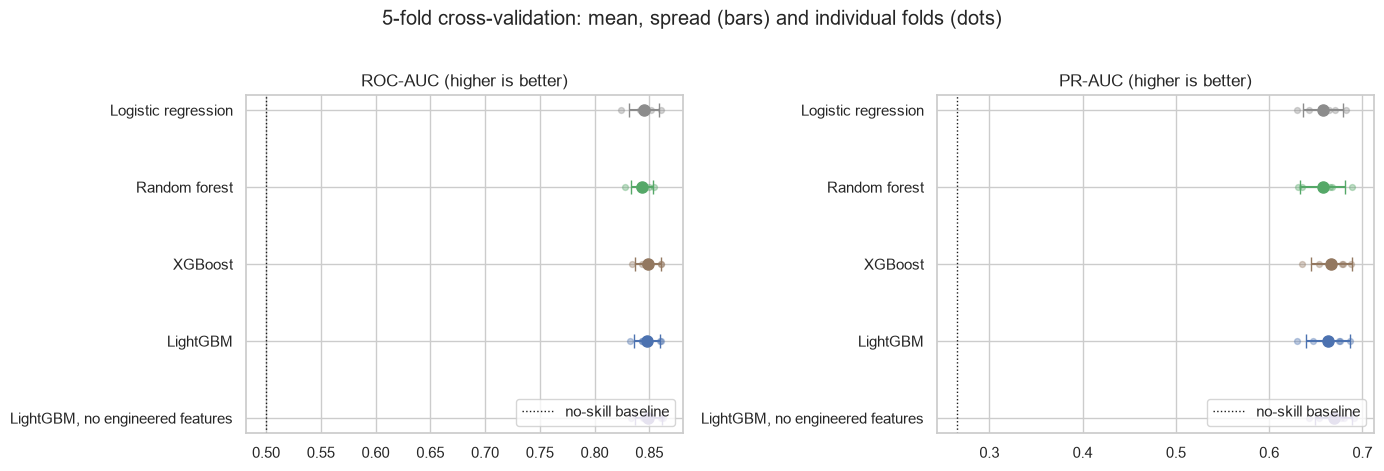

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
order = [n for n in cv_results if n != "Dummy (prior)"]
for ax, metric, title in zip(axes, ["roc_auc", "pr_auc"], ["ROC-AUC (higher is better)", "PR-AUC (higher is better)"]):
    for i, name in enumerate(order):
        vals = cv_results[name][metric]
        ax.errorbar(vals.mean(), i, xerr=vals.std(), fmt="o", color=MODEL_COLORS.get(name, "#4c72b0"), capsize=5, ms=8)
        ax.scatter(vals, [i] * len(vals), color=MODEL_COLORS.get(name, "#4c72b0"), alpha=0.35, s=18)
    ax.axvline(cv_results["Dummy (prior)"][metric].mean(), color="k", ls=":", lw=1, label="no-skill baseline")
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis(); ax.set_title(title); ax.legend(loc="lower right")
fig.suptitle("5-fold cross-validation: mean, spread (bars) and individual folds (dots)", y=1.02)
save_fig("model_comparison_cv.png")

**Reading the comparison.**
* The models are separated by **less than the fold-to-fold spread**. On a small, mostly categorical dataset (7,000 rows), a regularized **logistic regression is about as good as gradient boosting**. That is a real finding, not a failure of the boosted models: the signal is largely additive, and a simple model would be a defensible production choice.
* The **engineered features did not help** (the two LightGBM rows are indistinguishable). That is a negative result worth reporting, and when two models tie we prefer the simpler one, so the engineered features are dropped for the rest of the notebook.
* We carry **LightGBM** forward because it is at least as accurate and works with SHAP's exact, fast tree explanations, which the retention team will use.

In [10]:
# Simpler is better when accuracy ties: continue with the 26 original (non-engineered) features
X_train, X_test = X_train[plain_columns], X_test[plain_columns]
print(X_train.shape, X_test.shape)

(5634, 26) (1409, 26)


## 4. Tuning and final test evaluation

We tune LightGBM with a small randomized search (30 candidates, 5-fold CV, optimizing PR-AUC). The tuned CV score is slightly optimistic because the same folds picked the winner, so the final **test set** is what we trust.

In [11]:
search = RandomizedSearchCV(
    lgb.LGBMClassifier(random_state=SEED, verbose=-1, n_jobs=4, subsample_freq=1),
    param_distributions={"n_estimators": [150, 250, 400, 600], "learning_rate": [0.01, 0.02, 0.03, 0.05],
                         "num_leaves": [4, 6, 8, 12, 16], "min_child_samples": [20, 30, 50, 80],
                         "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.7, 0.9],
                         "reg_lambda": [1.0, 5.0, 10.0, 20.0], "reg_alpha": [0.0, 0.5, 2.0]},
    n_iter=30, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=1, refit=True)
search.fit(X_train, y_train)
best_params = search.best_params_
print("Best CV PR-AUC:", round(search.best_score_, 4))
print("Best params:", best_params)

make_tuned = lambda: lgb.LGBMClassifier(random_state=SEED, verbose=-1, n_jobs=4, subsample_freq=1, **best_params)
cv_results["LightGBM (tuned)"] = cv_scores(make_tuned(), X_train)
tuned = cv_results["LightGBM (tuned)"]
print(f"Tuned LightGBM:   ROC-AUC {tuned.roc_auc.mean():.3f} +/- {tuned.roc_auc.std():.3f} | PR-AUC {tuned.pr_auc.mean():.3f} +/- {tuned.pr_auc.std():.3f}")
for name in ["LightGBM", "Logistic regression"]:
    r = cv_results[name]
    print(f"{name + ':':<17} ROC-AUC {r.roc_auc.mean():.3f} +/- {r.roc_auc.std():.3f} | PR-AUC {r.pr_auc.mean():.3f} +/- {r.pr_auc.std():.3f}")

Best CV PR-AUC: 0.6701
Best params: {'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'num_leaves': 6, 'n_estimators': 400, 'min_child_samples': 50, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


Tuned LightGBM:   ROC-AUC 0.849 +/- 0.013 | PR-AUC 0.670 +/- 0.023
LightGBM:         ROC-AUC 0.848 +/- 0.012 | PR-AUC 0.663 +/- 0.024
Logistic regression: ROC-AUC 0.845 +/- 0.014 | PR-AUC 0.658 +/- 0.021


### Final model on the held-out test set

The test set is used **once**. We report point estimates with **bootstrap 95% confidence intervals**, because a single AUC on 1,409 customers has real sampling uncertainty.

LightGBM (tuned)       ROC-AUC 0.847 [0.826, 0.867] | PR-AUC 0.664 [0.612, 0.712] | Brier 0.135


Logistic regression    ROC-AUC 0.841 [0.817, 0.862] | PR-AUC 0.633 [0.578, 0.687] | Brier 0.138


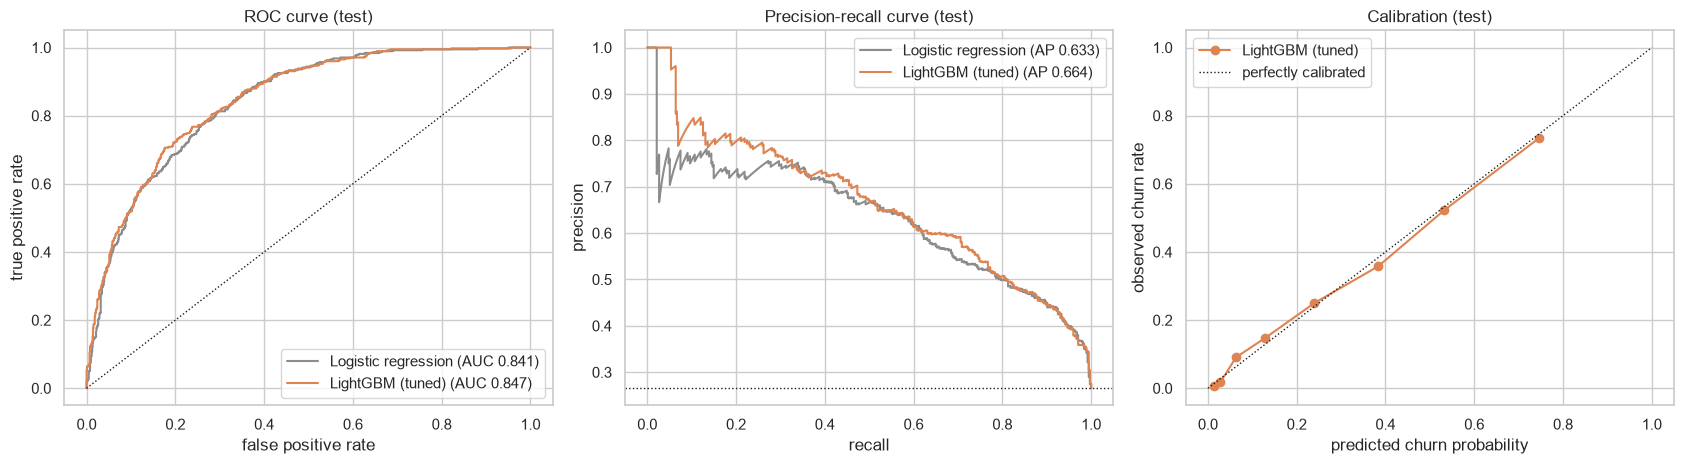

In [12]:
final_model = make_tuned().fit(X_train, y_train)
baseline_model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)).fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]
p_test_lr = baseline_model.predict_proba(X_test)[:, 1]

def bootstrap_ci(metric, y_true, scores, n=1000):
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true))
        vals.append(metric(y_true[i], scores[i]))
    return np.percentile(vals, [2.5, 97.5])

test_metrics = {}
for name, p in [("LightGBM (tuned)", p_test), ("Logistic regression", p_test_lr)]:
    roc, pr = roc_auc_score(y_test, p), average_precision_score(y_test, p)
    roc_ci, pr_ci = bootstrap_ci(roc_auc_score, y_test, p), bootstrap_ci(average_precision_score, y_test, p)
    test_metrics[name] = {"roc_auc": roc, "roc_auc_ci": roc_ci.tolist(), "pr_auc": pr, "pr_auc_ci": pr_ci.tolist(),
                          "brier": brier_score_loss(y_test, p)}
    print(f"{name:<22} ROC-AUC {roc:.3f} [{roc_ci[0]:.3f}, {roc_ci[1]:.3f}] | PR-AUC {pr:.3f} [{pr_ci[0]:.3f}, {pr_ci[1]:.3f}] | Brier {brier_score_loss(y_test, p):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for name, p in [("Logistic regression", p_test_lr), ("LightGBM (tuned)", p_test)]:
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})", color=MODEL_COLORS[name])
    pre, rec, _ = precision_recall_curve(y_test, p); axes[1].plot(rec, pre, label=f"{name} (AP {average_precision_score(y_test, p):.3f})", color=MODEL_COLORS[name])
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve (test)")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=1); axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall curve (test)")
axes[0].legend(loc="lower right"); axes[1].legend(loc="upper right")

frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=8, strategy="quantile")
axes[2].plot(mean_pred, frac_pos, "o-", color=MODEL_COLORS["LightGBM (tuned)"], label="LightGBM (tuned)")
axes[2].plot([0, 1], [0, 1], "k:", lw=1, label="perfectly calibrated"); axes[2].set(xlabel="predicted churn probability", ylabel="observed churn rate", title="Calibration (test)")
axes[2].legend()
save_fig("test_performance.png")

**Calibration matters here.** If the predicted probabilities track the observed churn rates (the right-hand panel hugs the diagonal), we can multiply them by dollar values and trust the result. That is what makes the profit analysis in section 6 meaningful.

## 5. Explaining the model with SHAP

AUC says the model ranks customers well; it does not say *why* a customer is high-risk. **SHAP** assigns each feature an additive contribution to each individual prediction (in log-odds), so we can answer both "what drives churn overall?" and "why is *this* customer flagged?".

SHAP values: (1409, 26) | base value (average log-odds): -1.619


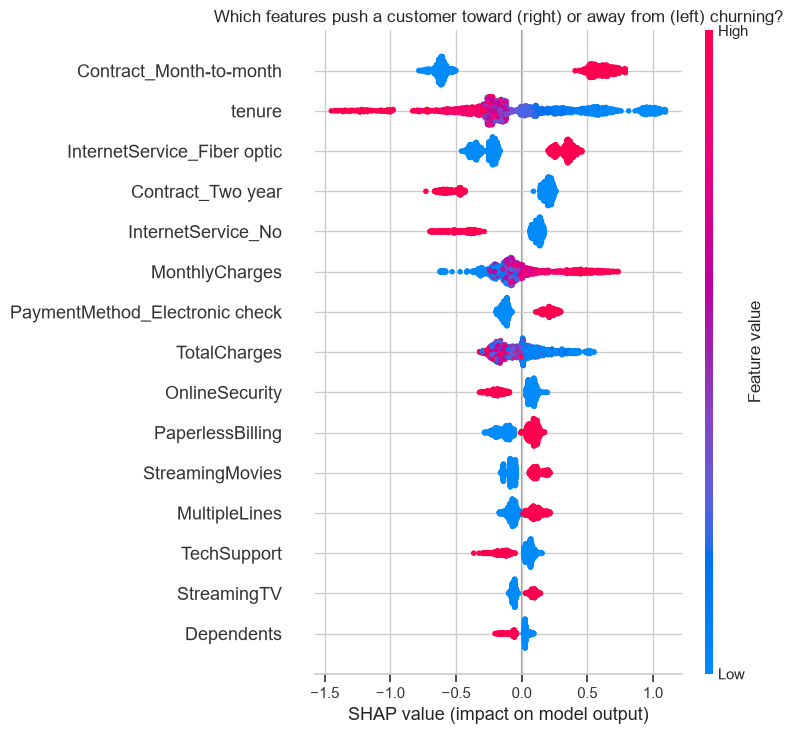

In [13]:
explainer = shap.TreeExplainer(final_model)
sv = explainer(X_test)                      # Explanation: values (n, features) in log-odds of churn
print("SHAP values:", sv.values.shape, "| base value (average log-odds):", round(float(np.mean(sv.base_values)), 3))

plt.figure(figsize=(9, 7))
shap.summary_plot(sv.values, X_test, max_display=15, show=False)
plt.title("Which features push a customer toward (right) or away from (left) churning?")
save_fig("shap_summary.png")

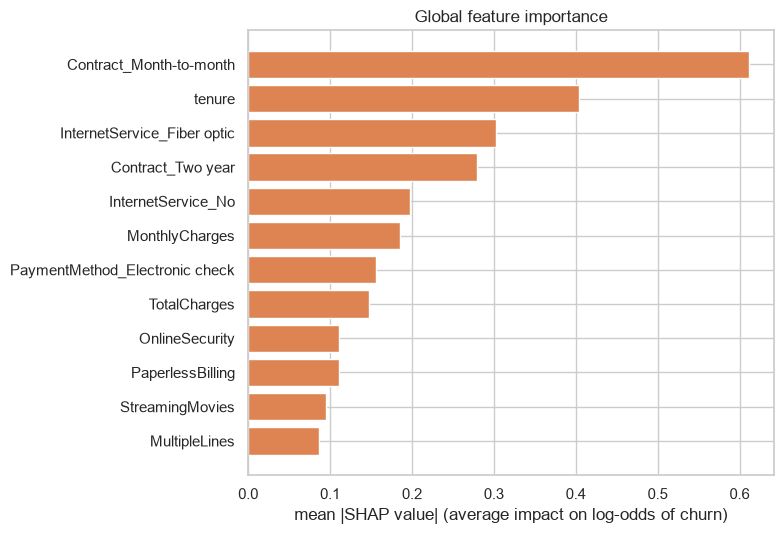

,mean |SHAP|
Contract_Month-to-month,0.612
tenure,0.404
InternetService_Fiber optic,0.303
Contract_Two year,0.279
InternetService_No,0.197
MonthlyCharges,0.186
PaymentMethod_Electronic check,0.156
TotalCharges,0.147
OnlineSecurity,0.111
PaperlessBilling,0.110


In [14]:
importance = pd.Series(np.abs(sv.values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
top = importance.head(12)[::-1]
ax.barh(top.index, top.values, color=PALETTE["churn"])
ax.set_xlabel("mean |SHAP value| (average impact on log-odds of churn)"); ax.set_title("Global feature importance")
save_fig("shap_importance.png")
importance.head(10).round(3).to_frame("mean |SHAP|")

Reading the beeswarm: each dot is one customer; colour is the feature value (red = high). For example, **low tenure** (blue dots) pushes the churn log-odds *up*, and a **month-to-month contract** pushes it up, while long contracts and long tenure protect against churn. These match the exploratory charts, but SHAP shows them *after controlling for the other features*.

Next, how the effect of the two most important numeric features actually behaves:

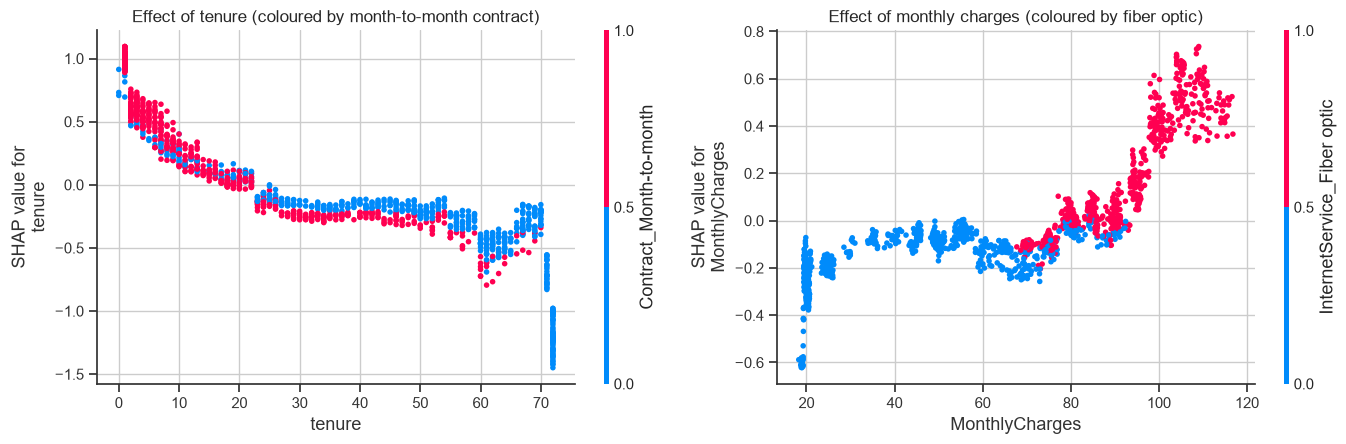

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
shap.dependence_plot("tenure", sv.values, X_test, interaction_index="Contract_Month-to-month", ax=axes[0], show=False)
axes[0].set_title("Effect of tenure (coloured by month-to-month contract)")
shap.dependence_plot("MonthlyCharges", sv.values, X_test, interaction_index="InternetService_Fiber optic", ax=axes[1], show=False)
axes[1].set_title("Effect of monthly charges (coloured by fiber optic)")
save_fig("shap_dependence.png")

### Explaining individual customers

This is the view a retention agent would actually use. Below, the highest-risk customer in the test set and a confidently loyal one.

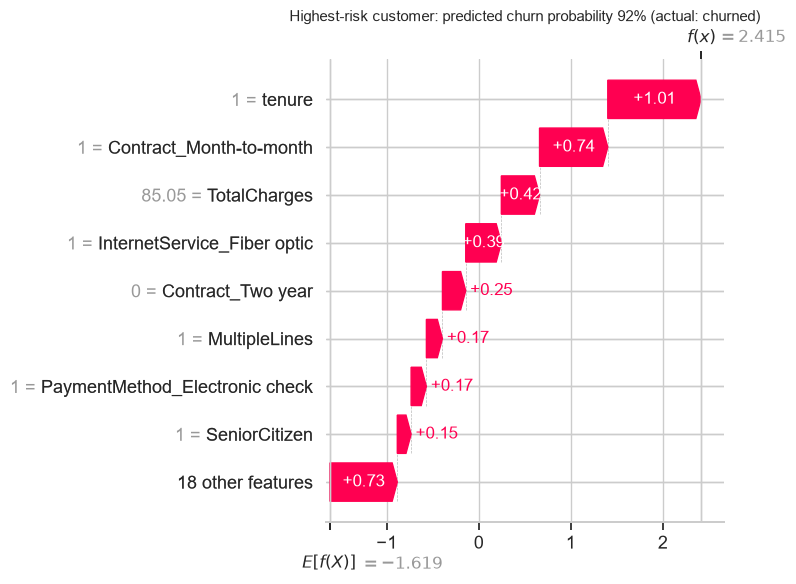

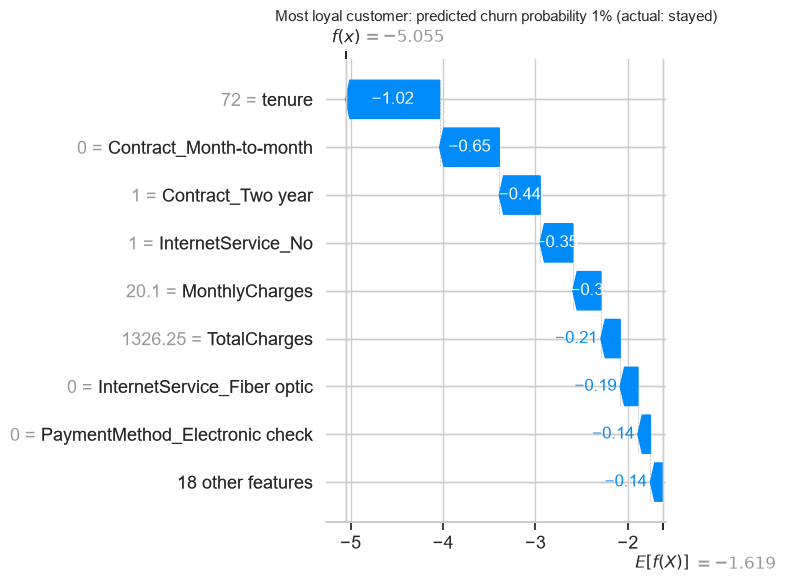

In [16]:
risk_order = np.argsort(p_test)
cases = {"Highest-risk customer": risk_order[-1], "Most loyal customer": risk_order[0]}
for title, i in cases.items():
    shap.plots.waterfall(sv[i], max_display=9, show=False)
    plt.title(f"{title}: predicted churn probability {p_test[i]:.0%} (actual: {'churned' if y_test[i] else 'stayed'})", fontsize=11)
    save_fig(f"shap_individual_{'high_risk' if i == risk_order[-1] else 'loyal'}.png")

## 6. From probabilities to profit: choosing the threshold

A churn model only creates value if it changes an action. The action here is a **retention offer**. We make the economics explicit:

| Assumption | Value | Meaning |
|---|---|---|
| Offer cost | **$100** per contacted customer | agent time plus roughly $10/month off for a year, paid to those who accept |
| Save rate | **40%** | share of would-be churners who stay after an offer |
| Value of a saved customer | **12 months of their `MonthlyCharges`** | revenue retained over the next year |

Contacting a customer who would have **stayed** anyway wastes the offer cost. Missing a churner forfeits the saved revenue. Under these assumptions a customer is worth contacting when

> `P(churn) x save rate x 12 x MonthlyCharges > offer cost`

We compare four policies, all judged on the held-out test set:
1. **Do nothing**, and 2. **contact everyone** (the two naive extremes),
3. **A single probability threshold** chosen to maximize profit on *out-of-fold training predictions* (never on the test set), compared with the default 0.5,
4. **A value-aware rule** that applies the formula above to each customer, so a high-bill customer is contacted at a lower risk than a low-bill one. It needs no tuning, but it relies on the probabilities being **calibrated**, which is why we checked calibration earlier.

*The dollar figures are illustrative assumptions; the sensitivity analysis below shows how the answer moves if they are wrong. In particular, when offers are cheap the best policy approaches "contact almost everyone", and the model earns its keep as offers get more expensive.*

In [17]:
COST_OFFER, SAVE_RATE, MONTHS_KEPT = 100.0, 0.40, 12

def profit_of(flagged, y_true, monthly, cost=COST_OFFER, save=SAVE_RATE):
    gain = save * MONTHS_KEPT * monthly * (y_true == 1)
    return float(np.sum(np.where(flagged, gain - cost, 0.0)))

def value_aware_flags(scores, monthly, cost=COST_OFFER, save=SAVE_RATE):
    return scores * save * MONTHS_KEPT * monthly >= cost

oof = cross_val_predict(make_tuned(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.linspace(0.02, 0.95, 94)
profit_oof = np.array([profit_of(oof >= t, y_train, monthly_train) for t in thresholds])
best_t = float(thresholds[profit_oof.argmax()])
print(f"Profit-maximizing threshold (chosen on out-of-fold training data): {best_t:.2f}")

def scenario(flagged, y_true, monthly):
    hit = int((flagged & (y_true == 1)).sum())
    return {"contacted": int(flagged.sum()), "share_contacted": float(flagged.mean()), "churners_reached": hit,
            "recall": hit / int((y_true == 1).sum()), "precision": hit / max(int(flagged.sum()), 1),
            "profit": profit_of(flagged, y_true, monthly)}

OPT_LABEL = f"Best single threshold ({best_t:.2f})"
VALUE_LABEL = "Value-aware rule (p x revenue > cost)"
policies = {
    "Do nothing": scenario(np.zeros(len(y_test), bool), y_test, monthly_test),
    "Contact everyone": scenario(np.ones(len(y_test), bool), y_test, monthly_test),
    "Default threshold 0.5": scenario(p_test >= 0.5, y_test, monthly_test),
    OPT_LABEL: scenario(p_test >= best_t, y_test, monthly_test),
    VALUE_LABEL: scenario(value_aware_flags(p_test, monthly_test), y_test, monthly_test),
}
table = pd.DataFrame(policies).T
pd.DataFrame({"contacted": table.contacted.astype(int), "% contacted": (100 * table.share_contacted).round(1),
              "churners reached": table.churners_reached.astype(int), "recall %": (100 * table.recall).round(1),
              "precision %": (100 * table.precision).round(1), "expected profit ($, test)": table.profit.round(0)})

Profit-maximizing threshold (chosen on out-of-fold training data): 0.38


,contacted,% contacted,churners reached,recall %,precision %,"expected profit ($, test)"
Do nothing,0,0.0,0,0.0,0.0,0.0
Contact everyone,1409,100.0,374,100.0,26.5,-10268.0
Default threshold 0.5,297,21.1,194,51.9,65.3,42959.0
Best single threshold (0.38),445,31.6,263,70.3,59.1,50863.0
Value-aware rule (p x revenue > cost),507,36.0,265,70.9,52.3,52959.0


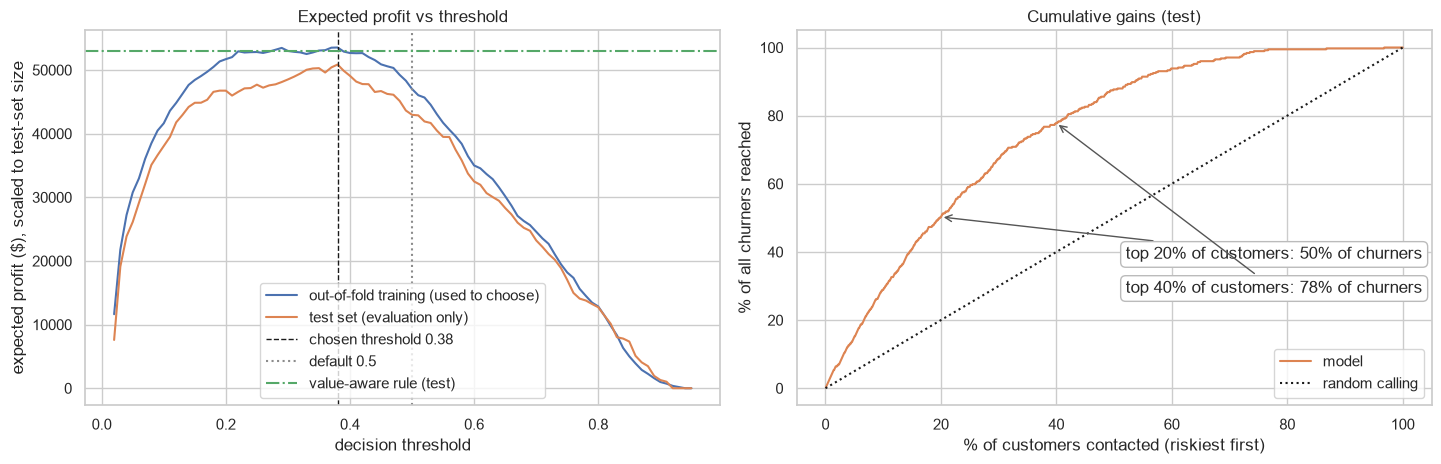

In [18]:
profit_test = np.array([profit_of(p_test >= t, y_test, monthly_test) for t in thresholds])
value_aware_profit = policies[VALUE_LABEL]["profit"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(thresholds, profit_oof / len(y_train) * len(y_test), label="out-of-fold training (used to choose)", color="#4c72b0")
axes[0].plot(thresholds, profit_test, label="test set (evaluation only)", color="#dd8452")
axes[0].axvline(best_t, color="k", ls="--", lw=1, label=f"chosen threshold {best_t:.2f}")
axes[0].axvline(0.5, color="#8c8c8c", ls=":", lw=1.5, label="default 0.5")
axes[0].axhline(value_aware_profit, color="#55a868", ls="-.", lw=1.5, label="value-aware rule (test)")
axes[0].set(xlabel="decision threshold", ylabel="expected profit ($), scaled to test-set size", title="Expected profit vs threshold"); axes[0].legend()

# cumulative gains: if we call the riskiest k% of customers, what share of churners do we reach?
order = np.argsort(-p_test); gains = np.cumsum(y_test[order]) / y_test.sum(); frac = np.arange(1, len(y_test) + 1) / len(y_test)
axes[1].plot(frac * 100, gains * 100, color="#dd8452", label="model"); axes[1].plot([0, 100], [0, 100], "k:", label="random calling")
for k, text_y in ((0.2, 38), (0.4, 28)):
    j = int(k * len(y_test)) - 1
    axes[1].annotate(f"top {k:.0%} of customers: {gains[j]:.0%} of churners", (k * 100, gains[j] * 100), (52, text_y), arrowprops=dict(arrowstyle="->", color="#555"),
                     bbox=dict(boxstyle="round", fc="white", ec="#bbb"))
axes[1].set(xlabel="% of customers contacted (riskiest first)", ylabel="% of all churners reached", title="Cumulative gains (test)"); axes[1].legend(loc="lower right")
save_fig("profit_and_gains.png")

### Sensitivity: what if our cost assumptions are wrong?

The business numbers are assumptions, so we re-optimize the threshold for a grid of offer costs and save rates and check how robust the policy is. We evaluate each re-optimized policy on the test set.

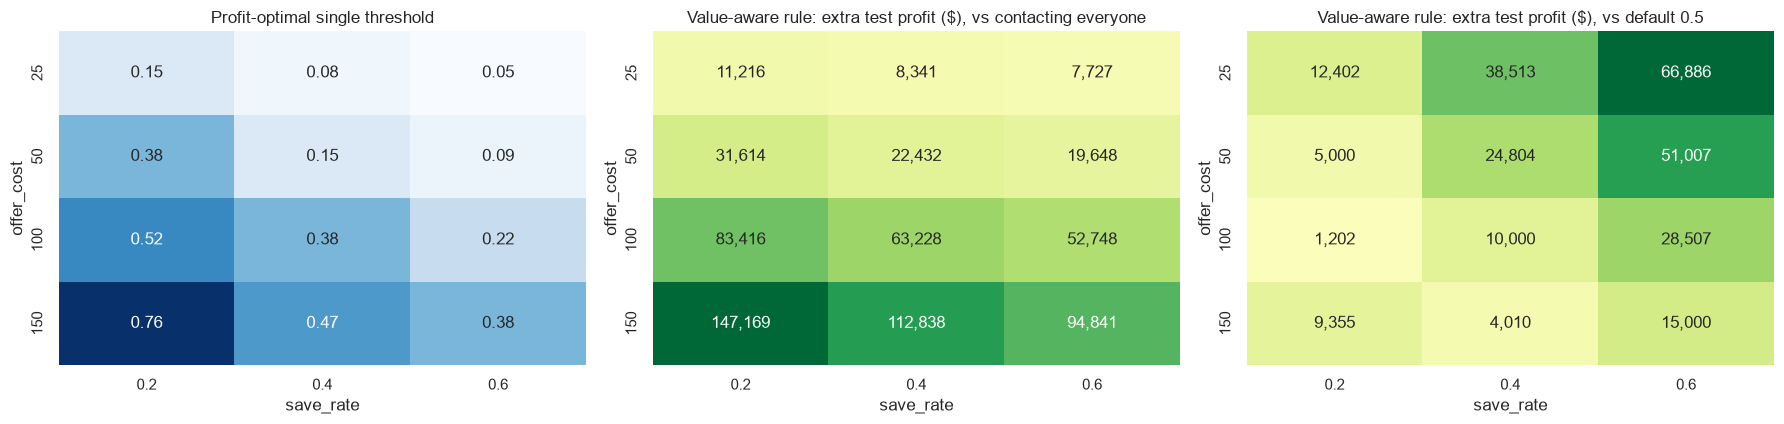

In [19]:
costs, saves = [25, 50, 100, 150], [0.2, 0.4, 0.6]
rows = []
for c in costs:
    for s in saves:
        pr_oof = np.array([profit_of(oof >= t, y_train, monthly_train, c, s) for t in thresholds])
        t_star = float(thresholds[pr_oof.argmax()])
        rows.append({"offer_cost": c, "save_rate": s, "threshold": t_star,
                     "best_threshold": profit_of(p_test >= t_star, y_test, monthly_test, c, s),
                     "value_aware": profit_of(value_aware_flags(p_test, monthly_test, c, s), y_test, monthly_test, c, s),
                     "contact_everyone": profit_of(np.ones(len(y_test), bool), y_test, monthly_test, c, s),
                     "default_0.5": profit_of(p_test >= 0.5, y_test, monthly_test, c, s)})
sens = pd.DataFrame(rows)
by = lambda col: sens.pivot(index="offer_cost", columns="save_rate", values=col)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
sns.heatmap(by("threshold"), annot=True, fmt=".2f", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Profit-optimal single threshold")
sns.heatmap(by("value_aware") - by("contact_everyone"), annot=True, fmt=",.0f", cmap="RdYlGn", center=0, ax=axes[1], cbar=False)
axes[1].set_title("Value-aware rule: extra test profit ($), vs contacting everyone")
sns.heatmap(by("value_aware") - by("default_0.5"), annot=True, fmt=",.0f", cmap="RdYlGn", center=0, ax=axes[2], cbar=False)
axes[2].set_title("Value-aware rule: extra test profit ($), vs default 0.5")
save_fig("sensitivity.png")

## 7. Findings, recommendations and limitations

The next cell prints the headline numbers straight from this run, so the text below can never drift from the results.

In [20]:
opt, d50, every, va = policies[OPT_LABEL], policies["Default threshold 0.5"], policies["Contact everyone"], policies[VALUE_LABEL]
lg, lr = test_metrics["LightGBM (tuned)"], test_metrics["Logistic regression"]
print(f"Test ROC-AUC  LightGBM {lg['roc_auc']:.3f} (95% CI {lg['roc_auc_ci'][0]:.3f}-{lg['roc_auc_ci'][1]:.3f})  vs  logistic regression {lr['roc_auc']:.3f}")
print(f"Test PR-AUC   LightGBM {lg['pr_auc']:.3f}  vs  logistic regression {lr['pr_auc']:.3f}  (churn base rate {y_test.mean():.3f})")
print(f"Best single threshold ({best_t:.2f}): contact {opt['share_contacted']:.0%}, reach {opt['recall']:.0%} of churners, expected profit ${opt['profit']:,.0f}")
print(f"Value-aware rule:        contact {va['share_contacted']:.0%}, reach {va['recall']:.0%} of churners, expected profit ${va['profit']:,.0f}")
print(f"Default 0.5 threshold: ${d50['profit']:,.0f}   |   contact everyone: ${every['profit']:,.0f}   |   do nothing: $0")
print("Top SHAP drivers:", ", ".join(importance.head(5).index))

Test ROC-AUC  LightGBM 0.847 (95% CI 0.826-0.867)  vs  logistic regression 0.841
Test PR-AUC   LightGBM 0.664  vs  logistic regression 0.633  (churn base rate 0.265)
Best single threshold (0.38): contact 32%, reach 70% of churners, expected profit $50,863
Value-aware rule:        contact 36%, reach 71% of churners, expected profit $52,959
Default 0.5 threshold: $42,959   |   contact everyone: $-10,268   |   do nothing: $0
Top SHAP drivers: Contract_Month-to-month, tenure, InternetService_Fiber optic, Contract_Two year, InternetService_No


**Findings**
1. The model ranks churners well (see the ROC-AUC with confidence interval above), but **a regularized logistic regression performs within the noise of gradient boosting**. On small, mostly-categorical tabular data, model complexity buys little.
2. The strongest churn drivers are **contract type, tenure, and internet service / monthly charges**. Customers on month-to-month plans in their first months, especially on fiber optic, are the high-risk group.
3. The model's probabilities are **well calibrated** (the calibration curve hugs the diagonal), so they can be combined with dollar values.
4. **The decision rule matters more than the model.** With a $100 offer, contacting everyone *loses* money, the default 0.5 threshold leaves roughly $10k on the table (on a 1,409-customer test set), and the profit-based policies do best. The value-aware rule is the best policy and needs no tuning; it beats both naive extremes in **all 12** cost scenarios of the sensitivity grid, though its edge over a well-tuned single threshold is small.

**Recommendations**
* Target retention offers by **expected profit** (probability x revenue at risk - offer cost), not by a flat probability cut-off.
* Use the SHAP explanation to pick the *message*: a short-tenure month-to-month customer is a candidate for a **contract-upgrade incentive**; a high-charge fiber customer may need a **price or service review** instead of a generic discount.
* Treat the first months of a customer's life as a retention window: onboarding quality likely matters more than any later offer.

**Limitations and honest caveats**
* The dollar assumptions (offer cost, save rate, 12-month value) are **illustrative**. In practice the save rate should be measured with an A/B test of the offer, because the model predicts *who will leave*, not *who can be persuaded to stay*. These are different populations, and a proper uplift model needs experimental data.
* The data is a **single snapshot** with one label per customer; there is no time dimension, so we cannot test how the model degrades as behaviour changes. A production system would need drift monitoring and periodic retraining.
* SHAP shows what the *model* relies on, which is association, not proof that changing a feature (e.g. moving a customer to a contract) would change their behaviour.
* Only 7,043 customers: the confidence intervals above are wide enough that small AUC differences between models should not be over-interpreted.

In [21]:
# Persist the artifacts: model, metrics and the exact decision policy
joblib.dump({"model": final_model, "feature_names": list(X_train.columns), "threshold": best_t}, OUT_DIR / "churn_lightgbm.joblib")
metrics = {
    "cv": {name: {m: [float(v) for v in r[m]] for m in ["roc_auc", "pr_auc", "brier"]} for name, r in cv_results.items()},
    "test": test_metrics,
    "best_params": {k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in best_params.items()},
    "decision": {"threshold": best_t, "assumptions": {"offer_cost": COST_OFFER, "save_rate": SAVE_RATE, "months_kept": MONTHS_KEPT},
                 "policies": {k: {a: float(b) for a, b in v.items()} for k, v in policies.items()}},
    "top_shap_features": importance.head(10).round(4).to_dict(),
    "n_train": int(len(y_train)), "n_test": int(len(y_test)), "churn_rate": float(y.mean()),
}
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
print("Saved:", sorted(p.name for p in OUT_DIR.iterdir()))

Saved: ['churn_lightgbm.joblib', 'metrics.json']
